## SER Experiments — Bank8FM Dataset 

# Segmentation Expert-Mixture Regularization (SER)
### CAIAC 2026

### Author: Sarah Elyane Rashiwa, Paula Branco
### University of Ottawa


In [1]:
import sys
sys.path.append("../src")

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.linear_model import HuberRegressor
from sklearn.metrics import (
    r2_score,
    mean_absolute_error,
    mean_squared_error
)

from ser import run_pipeline

In [2]:
df = pd.read_csv("../data/Bank8FM.csv")

df.head()

,rej,a1cx,a1cy,b2x,b2y,a2pop,a3pop,temp,mxql
0,0.657019,-0.102111,-0.193977,-0.385334,0.257042,7.188886,15.128160,0.671618,8
1,0.143680,0.373578,-0.425602,0.289500,0.234217,2.028584,2.856180,0.569577,5
2,0.264202,0.385361,0.108340,-0.048971,-0.147634,4.073232,3.616225,0.126882,6
3,0.003634,0.316211,-0.134321,0.080048,0.036333,0.360257,1.069743,0.807717,8
4,0.004023,0.007116,0.295712,0.007483,-0.456627,0.072030,0.968635,0.188453,7


In [3]:
print(df.shape)
print(df.columns)

(4499, 9)
Index(['rej', 'a1cx', 'a1cy', 'b2x', 'b2y', 'a2pop', 'a3pop', 'temp', 'mxql'], dtype='object')


In [4]:
X = df.drop(columns=["rej"]).copy()
y = df["rej"].copy()

In [5]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.30,
    random_state=42
)

### SER A

In [6]:
results_A = run_pipeline(
    X_train,
    y_train,
    X_test,
    y_test,
    method="A",
    alpha_ratio=0.05,
    verbose=True
)

results_A["metrics"]


 PIPELINE – method A
Train: 3149, Test: 1350




 Tailles des groupes :
Lower : 0 / Center : 2681 / Upper : 468
Groupe Lower ignored (n=0)

 Final prediction (test set) - method : A
  Model        R2       MAE     RMSE
0   SER  0.957287  0.024188  0.03181


,Model,R2,MAE,RMSE
0,SER,0.957287,0.024188,0.03181


### SER B

In [7]:
results_B = run_pipeline(
    X_train,
    y_train,
    X_test,
    y_test,
    method="B",
    
    verbose=True
)

results_B["metrics"]


 PIPELINE – method B
Train: 3149, Test: 1350


 Tailles des groupes :
Lower : 315 / Center : 2519 / Upper : 315

 Final prediction (test set) - method : B
  Model        R2       MAE      RMSE
0   SER  0.959655  0.023165  0.030916


,Model,R2,MAE,RMSE
0,SER,0.959655,0.023165,0.030916


### SER C

In [8]:
results_C = run_pipeline(
    X_train,
    y_train,
    X_test,
    y_test,
    method="C",
    verbose=True
)

results_C["metrics"]


 PIPELINE – method C
Train: 3149, Test: 1350


 Tailles des groupes :
Lower : 0 / Center : 3099 / Upper : 50
Groupe Lower ignored (n=0)


c:\Users\srash\anaconda3\Lib\site-packages\sklearn\linear_model\_huber.py:342: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. of ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
  self.n_iter_ = _check_optimize_result("lbfgs", opt_res, self.max_iter)



 Final prediction (test set) - method : C
  Model        R2       MAE      RMSE
0   SER  0.938817  0.027648  0.038072


,Model,R2,MAE,RMSE
0,SER,0.938817,0.027648,0.038072


### SER D

In [9]:
results_D = run_pipeline(
    X_train,
    y_train,
    X_test,
    y_test,
    method="D",
    verbose=True
)

results_D["metrics"]


 PIPELINE – method D
Train: 3149, Test: 1350


 Tailles des groupes :
Lower : 945 / Center : 1259 / Upper : 945

 Final prediction (test set) - method : D
  Model        R2       MAE      RMSE
0   SER  0.958852  0.022919  0.031222


,Model,R2,MAE,RMSE
0,SER,0.958852,0.022919,0.031222


### Results Comparison

In [10]:
# ==========================================================
# COMPARISON TABLE — SER vs OLS vs HUBER
# ==========================================================

# OLS metrics
ols_metrics = pd.DataFrame([{
    "Model": "OLS",
    "R2": r2_score(y_test, results_A["pred_naive"]),
    "MAE": mean_absolute_error(y_test, results_A["pred_naive"]),
    "RMSE": np.sqrt(mean_squared_error(y_test, results_A["pred_naive"]))
}])


# Huber baseline
huber = HuberRegressor(epsilon=1.35, alpha=0.0)

huber.fit(
    X_train.to_numpy(),
    y_train.to_numpy()
)

huber_pred = huber.predict(
    X_test.to_numpy()
)

huber_metrics = pd.DataFrame([{
    "Model": "Huber",
    "R2": r2_score(y_test, huber_pred),
    "MAE": mean_absolute_error(y_test, huber_pred),
    "RMSE": np.sqrt(mean_squared_error(y_test, huber_pred))
}])


# SER metrics
ser_metrics = pd.concat([
    results_A["metrics"].assign(Model="SER-A"),
    results_B["metrics"].assign(Model="SER-B"),
    results_C["metrics"].assign(Model="SER-C"),
    results_D["metrics"].assign(Model="SER-D")
], ignore_index=True)


# Final table
all_results = pd.concat([
    ols_metrics,
    huber_metrics,
    ser_metrics
], ignore_index=True)

all_results = all_results.sort_values(
    by="R2",
    ascending=False
).reset_index(drop=True)

all_results

,Model,R2,MAE,RMSE
0,SER-B,0.959655,0.023165,0.030916
1,SER-D,0.958852,0.022919,0.031222
2,SER-A,0.957287,0.024188,0.031810
3,SER-C,0.938817,0.027648,0.038072
4,OLS,0.930704,0.028872,0.040518
5,Huber,0.929177,0.028432,0.040962


### True VS Predicted

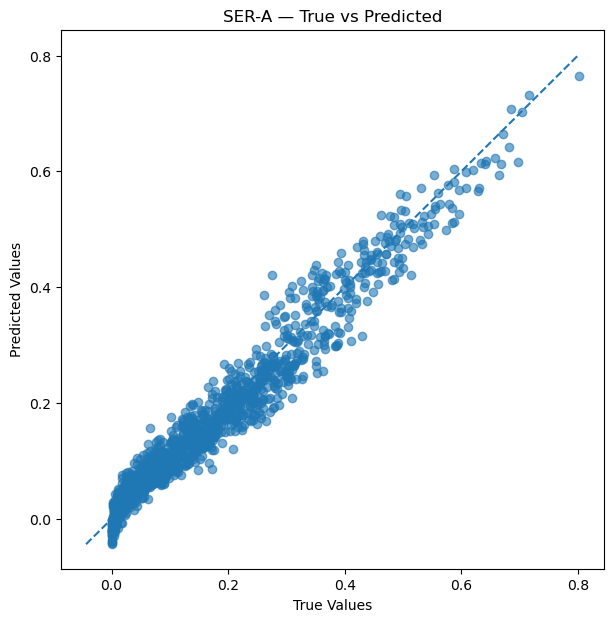

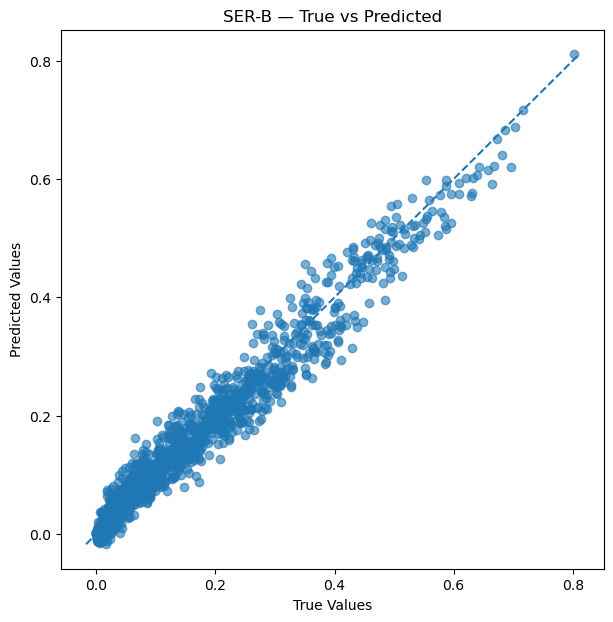

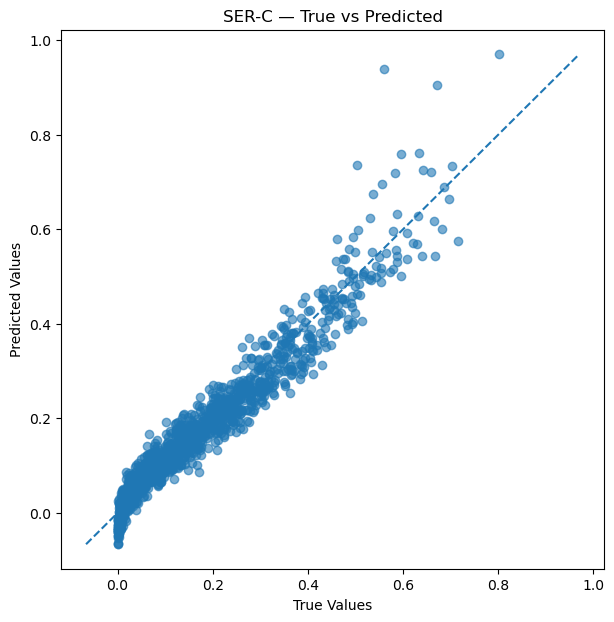

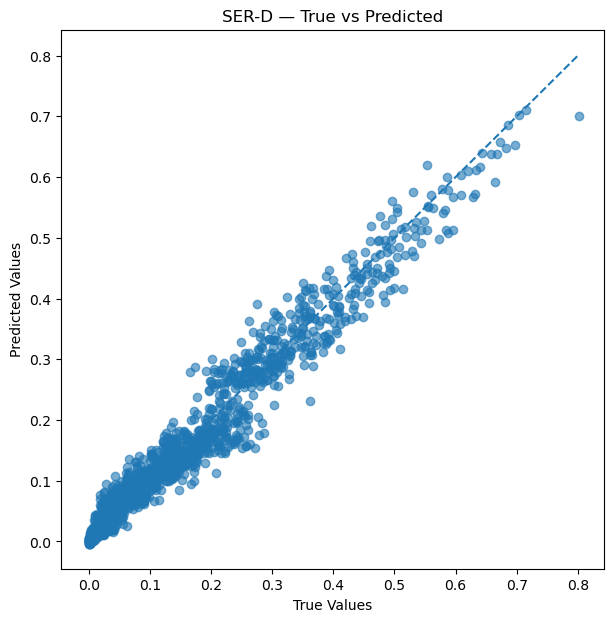

In [11]:
# ==========================================================
# SAVE TRUE VS PREDICTED FIGURES — ALL SER METHODS
# ==========================================================

methods_results = {
    "SER-A": results_A,
    "SER-B": results_B,
    "SER-C": results_C,
    "SER-D": results_D
}

for method_name, result in methods_results.items():

    plt.figure(figsize=(7, 7))

    plt.scatter(
        y_test,
        result["pred_blend"],
        alpha=0.6
    )

    min_val = min(y_test.min(), result["pred_blend"].min())
    max_val = max(y_test.max(), result["pred_blend"].max())

    plt.plot(
        [min_val, max_val],
        [min_val, max_val],
        linestyle="--"
    )

    plt.xlabel("True Values")
    plt.ylabel("Predicted Values")
    plt.title(f"{method_name} — True vs Predicted")

    plt.savefig(
        f"../figures/Bank8FM_{method_name}_true_vs_predicted.png",
        bbox_inches="tight"
    )

    plt.show()

### Save CSV

In [12]:
all_results.to_csv(
    "../results/Bank8FM_results.csv",
    index=False
)